# T-22 微型感測器校正：共置比對與濕度（初步）

**目的：**⑤ Analytics Engine 的校正步驟要回答兩件事：
1. 微型感測器和國家測站差多少？簡單的線性校正有沒有用？
2. 濕度要用哪一個來源？（T-20 發現臺中微型感測器自己回報的濕度不可靠）

**資料：**2026-10-19 起排程收集的多天資料（微型感測器、國家測站、氣象站，見第一個程式格的輸出）。
**方法：**`src/analytics/calibration.py`。國家測站 1 km 內的微型感測器先各自算小時平均，再取中位數；用留一站交叉驗證評估校正。

In [1]:
import os, sys, glob, warnings
from pathlib import Path
ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
os.chdir(ROOT); sys.path.insert(0, str(ROOT)); warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from src.analytics import calibration as cal

plt.rcParams.update({"font.sans-serif": ["Microsoft JhengHei", "Noto Sans CJK TC", "sans-serif"],
                     "axes.unicode_minus": False, "figure.dpi": 110, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.color": "#e6e5e1",
                     "grid.linewidth": 0.6, "axes.edgecolor": "#52514e", "text.color": "#0b0b0b",
                     "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
                     "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb"})
BLUE, ORANGE, INK2 = "#2a78d6", "#eb6834", "#52514e"
FIG = ROOT / "notebooks" / "figures"; FIG.mkdir(parents=True, exist_ok=True)
CITIES = ["臺中市", "高雄市"]; SINCE = "2026-10-19"

def read(path, **kw):
    df = pd.read_csv(path, **kw); df["time"] = pd.to_datetime(df["time"]).dt.tz_convert("Asia/Taipei"); return df

def read_days(source, city, key):
    files = [f for f in sorted(glob.glob(str(ROOT / f"data/raw/{source}/{city}/*.csv.gz"))) if Path(f).name[:10] >= SINCE]
    return pd.concat([read(f, dtype={key: str}) for f in files], ignore_index=True).drop_duplicates([key, "time"])

colife = {c: read_days("colife", c, "station_id") for c in CITIES}
moenv = {c: read_days("moenv", c, "siteid") for c in CITIES}
cwa = {c: read_days("cwa", c, "station_id") for c in CITIES}
for c in CITIES:
    print(f"{c}: 微型感測器 {colife[c]['time'].min():%m/%d %H:%M}～{colife[c]['time'].max():%m/%d %H:%M}；"
          f"氣象站 {cwa[c]['time'].nunique()} 個觀測時間")

臺中市: 微型感測器 10/19 11:30～10/24 11:35；氣象站 116 個觀測時間
高雄市: 微型感測器 10/19 11:00～10/24 11:30；氣象站 116 個觀測時間


## 1. 國家測站的小時標記慣例

測站 13:00 的值代表 12:00～12:59 還是 13:00～13:59？我們沒有找到可引用的官方說明（待查證），所以用資料比對：
兩種對齊方式下，微型感測器與測站的相關係數。

In [2]:
align = pd.concat([cal.best_alignment(colife[c], moenv[c], r).assign(city=c, radius_km=r)
                   for c in CITIES for r in (1.0, 2.0)])
align.round(3)

,label,n_pairs,r,MAE,city,radius_km
0,end,704,0.841,5.308,臺中市,1.0
1,start,710,0.864,4.969,臺中市,1.0
0,end,704,0.869,5.252,臺中市,2.0
1,start,710,0.890,4.914,臺中市,2.0
0,end,1299,0.798,3.753,高雄市,1.0
1,start,1310,0.857,3.432,高雄市,1.0
0,end,1418,0.814,3.648,高雄市,2.0
1,start,1430,0.865,3.364,高雄市,2.0


In [3]:
# 相關係數在兩市、兩種半徑都是 start 較高 → 以 start（13:00 代表 13:00～13:59）為準，之後有官方說明再確認
LABEL = "start"
pairs = pd.concat([cal.collocate(cal.hourly_sensor_means(colife[c], LABEL), moenv[c], radius_km=1.0).assign(city=c)
                   for c in CITIES], ignore_index=True)
summary = pairs.groupby(["city", "sitename"]).agg(小時數=("ref_pm25", "size"), 測站=("ref_pm25", "mean"),
                                                  微型感測器=("sensor_pm25", "mean"), 感測器數=("n_sensors", "median"))
summary.round(1)

小時數    測站  微型感測器  感測器數
city sitename                        
臺中市  大里        118  11.5   15.8  21.0
     忠明        119  12.5   17.5   7.0
     沙鹿        115  14.7   16.7  12.0
     臺灣大道      119  14.9   18.3   8.0
     西屯        119  13.8   15.1   7.0
     豐原        120  11.1   14.0  13.0
高雄市  仁武        120  14.0   15.1   8.0
     前金        118  13.2   14.5  21.0
     前鎮        118  13.0   14.0   8.0
     大寮        120  17.3   15.0  16.0
     小港        119  16.6   13.3  20.0
     左營        119  13.9   12.6   5.0
     復興        118  14.9   13.4  10.0
     林園        120  18.1   14.9  12.0
     楠梓        120  14.0   13.2   9.0
     橋頭        120  14.8   14.1  14.0
     鳳山        118  17.5   12.8   8.0

## 2. 線性校正（留一站交叉驗證）

In [4]:
MODELS = {"不校正": [], "線性": ["sensor_pm25"], "線性＋測站濕度": ["sensor_pm25", "station_rh"]}
cv = pd.concat([cal.leave_one_site_out(pairs[pairs.city == c].reset_index(drop=True), MODELS).assign(city=c)
                for c in CITIES])
cv["MAE 改善"] = 1 - cv["MAE"] / cv.groupby("city")["MAE"].transform("first")
print(cv.round(2).to_string(index=False))
for c in CITIES:
    p = pairs[pairs.city == c]
    print(f"\n{c} 全部資料的係數：", cal.fit(p, ["sensor_pm25"]).round(3).to_dict(),
          cal.fit(p, ["sensor_pm25", "station_rh"]).round(3).to_dict(),
          f"；r = {p['sensor_pm25'].corr(p['ref_pm25']):.2f}；測站濕度 {p['station_rh'].min():.0f}～{p['station_rh'].max():.0f}%")

  model    n  MAE  RMSE  bias city  MAE 改善
    不校正  710 4.97  5.89  3.17  臺中市    0.00
     線性  710 4.00  5.21  0.07  臺中市    0.20
線性＋測站濕度  710 3.85  5.07  0.09  臺中市    0.22
    不校正 1310 3.43  4.36 -1.31  高雄市    0.00
     線性 1310 3.18  4.02 -0.00  高雄市    0.07
線性＋測站濕度 1308 3.05  3.86 -0.01  高雄市    0.11

臺中市 全部資料的係數： {'intercept': -4.553, 'sensor_pm25': 1.085} {'intercept': 3.162, 'sensor_pm25': 1.101, 'station_rh': -0.104} ；r = 0.86；測站濕度 40～100%

高雄市 全部資料的係數： {'intercept': -2.624, 'sensor_pm25': 1.283} {'intercept': 5.385, 'sensor_pm25': 1.23, 'station_rh': -0.095} ；r = 0.86；測站濕度 46～100%


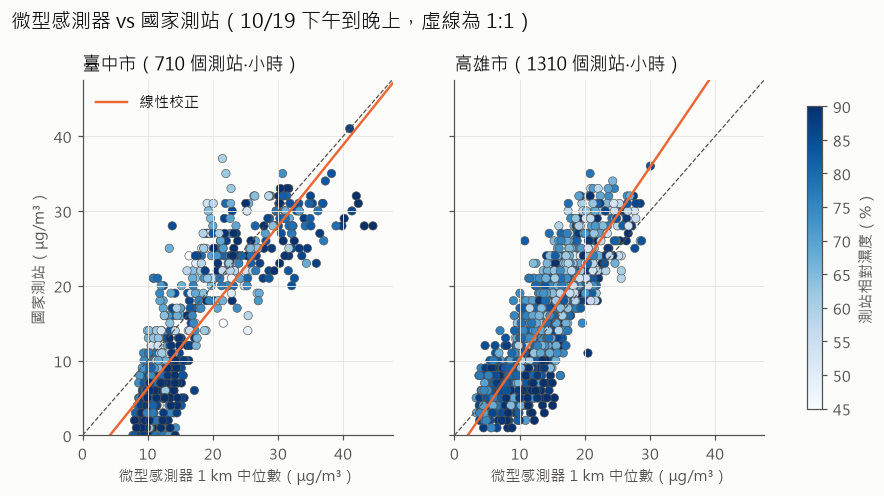

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4.2), sharex=True, sharey=True)
lim = [0, max(pairs["ref_pm25"].max(), pairs["sensor_pm25"].max()) + 3]
for ax, c in zip(axes, CITIES):
    p = pairs[pairs.city == c]
    sc = ax.scatter(p["sensor_pm25"], p["ref_pm25"], c=p["station_rh"], cmap="Blues", vmin=45, vmax=90,
                    edgecolor=INK2, linewidth=0.4, s=30)
    ax.plot(lim, lim, color=INK2, lw=0.8, ls="--")
    k = cal.fit(p, ["sensor_pm25"]); x = np.array(lim)
    ax.plot(x, k["intercept"] + k["sensor_pm25"] * x, color=ORANGE, lw=1.6, label="線性校正")
    ax.set_title(f"{c}（{len(p)} 個測站‧小時）", loc="left", fontsize=12); ax.set_xlabel("微型感測器 1 km 中位數（μg/m³）")
    ax.set_xlim(lim); ax.set_ylim(lim)
axes[0].set_ylabel("國家測站（μg/m³）"); axes[0].legend(frameon=False, loc="upper left")
fig.colorbar(sc, ax=axes, label="測站相對濕度（%）", shrink=0.85)
fig.suptitle("微型感測器 vs 國家測站（10/19 下午到晚上，虛線為 1:1）", x=0.06, y=1.03, ha="left", fontsize=13)
fig.savefig(FIG / "t22_fig1_collocation.png", dpi=160, bbox_inches="tight")

## 3. 三種濕度來源的比較

In [6]:
near = pd.concat([cal.nearest_weather(moenv[c], cwa[c]) for c in CITIES])
w = pd.concat(cwa.values())[["station_id", "time", "rh"]].rename(columns={"station_id": "cwa_id", "rh": "cwa_rh"})
w["time"] = w["time"].dt.floor("h")
rh = pairs.merge(near, on="siteid").merge(w, on=["cwa_id", "time"], how="left")
rows = []
for c in CITIES:
    r = rh[rh.city == c]
    for name, col in [("微型感測器自己回報", "sensor_rh"), ("最近的氣象站", "cwa_rh")]:
        ok = r[[col, "station_rh"]].dropna()
        rows.append({"city": c, "濕度來源": name, "n": len(ok), "平均（%）": ok[col].mean(),
                     "測站平均（%）": ok["station_rh"].mean(), "與測站差的平均絕對值": (ok[col] - ok["station_rh"]).abs().mean()})
rh_table = pd.DataFrame(rows); print(rh_table.round(1).to_string(index=False))
print("\n測站到最近氣象站的距離（km）：", near["cwa_km"].describe().round(1).to_dict())

city      濕度來源    n  平均（%）  測站平均（%）  與測站差的平均絕對值
 臺中市 微型感測器自己回報  710   97.7     76.9        24.0
 臺中市    最近的氣象站  677   78.7     77.6         5.5
 高雄市 微型感測器自己回報 1308   73.0     76.8         4.7
 高雄市    最近的氣象站 1236   77.6     77.2         3.9

測站到最近氣象站的距離（km）： {'count': 18.0, 'mean': 2.1, 'std': 1.1, 'min': 0.0, '25%': 1.5, '50%': 2.1, '75%': 2.8, 'max': 4.0}


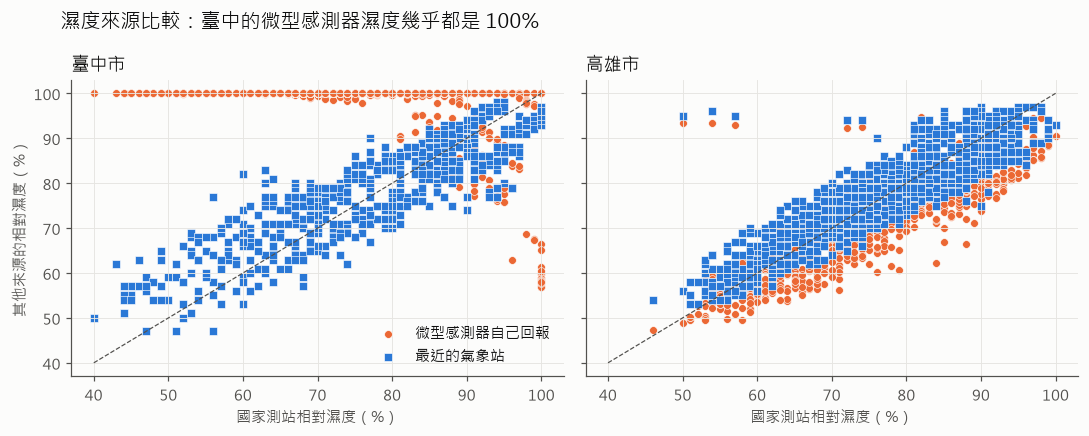

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharex=True, sharey=True)
for ax, c in zip(axes, CITIES):
    r = rh[rh.city == c]
    ax.scatter(r["station_rh"], r["sensor_rh"], color=ORANGE, s=26, label="微型感測器自己回報", edgecolor="white", linewidth=0.4)
    ax.scatter(r["station_rh"], r["cwa_rh"], color=BLUE, s=26, marker="s", label="最近的氣象站", edgecolor="white", linewidth=0.4)
    ax.plot([40, 100], [40, 100], color=INK2, lw=0.8, ls="--")
    ax.set_title(c, loc="left", fontsize=12); ax.set_xlabel("國家測站相對濕度（%）")
axes[0].set_ylabel("其他來源的相對濕度（%）"); axes[0].legend(frameon=False, loc="lower right")
fig.suptitle("濕度來源比較：臺中的微型感測器濕度幾乎都是 100%", x=0.06, ha="left", fontsize=13)
fig.tight_layout(); fig.savefig(FIG / "t22_fig2_humidity_sources.png", dpi=160)

## 結論（5 天資料，2026-10-19～10-24）

見 `coordination/reports/T-22.md`。重點：
- 國家測站的小時標記，「13:00＝13:00～13:59」在兩市、兩種半徑都較吻合（官方說明仍待查證）。
- 留一站交叉驗證：線性＋測站濕度校正，臺中 MAE 改善 22%、高雄改善 11%。單日資料時高雄改善 54% 是偶然結果。
- 微型感測器在臺中偏高（平均 +3.2）、高雄偏低（−1.3），校正必須在地化，不能共用一組係數（呼應 S-010）。
- 濕度係數兩市都約為 −0.10（濕度越高，感測器越高估），方向與 S-008、S-009 一致；但濕度和時段仍有相關，**不能單獨當成濕度效應的證據**。
- 臺中微型感測器回報的濕度平均 97.7%（測站 76.9%），不能用；最近氣象站的濕度與測站只差約 5%，可作為沒有測站地方的濕度來源。